In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [73]:
df = pd.read_csv('titanic_data_updated.csv')

In [74]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    str    
 2   Pclass       891 non-null    str    
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(3), str(7)
memory usage: 125.5 KB


In [76]:
df.shape

(891, 12)

In [77]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
141,142,yes,third,"Nysten, Miss. Anna Sofia",female,22.0,0,0,347081,7.75,NaN,S
61,62,yes,first,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.00,B28,NaN
612,613,yes,third,"Murphy, Miss. Margaret Jane",female,NaN,1,0,367230,15.50,NaN,Q
466,467,no,second,"Campbell, Mr. William",male,NaN,0,0,239853,0.00,NaN,S
781,782,yes,first,"Dick, Mrs. Albert Adrian (Vera Gillespie)",female,17.0,1,0,17474,57.00,B20,S


In [78]:
#missing value
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [79]:
#Checking duplicate values

df.duplicated().sum()

#Drop duplicate values
df.drop_duplicates(inplace = True)

In [80]:
df.describe()

,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


Univariate analysis(categorical)

<Axes: xlabel='Survived', ylabel='count'>

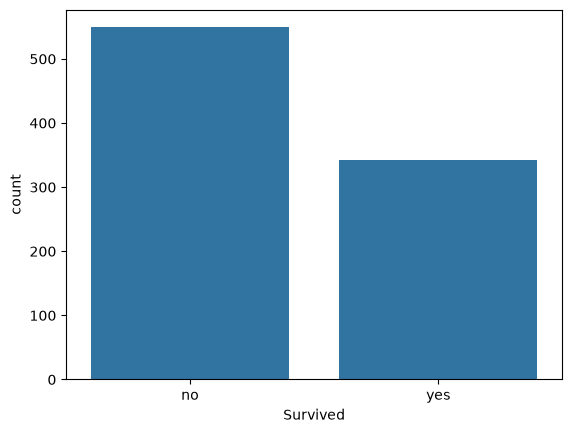

In [81]:
sns.countplot(data = df, x = df['Survived'])

In [82]:
(df['Survived'].value_counts()/len(df))* 100

Survived
no     61.616162
yes    38.383838
Name: count, dtype: float64

In [83]:
survived_count = df['Survived'].value_counts()
survived_label = df['Survived'].unique()

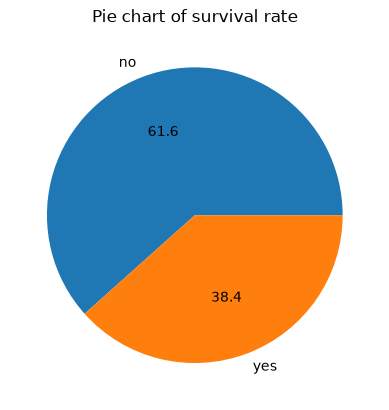

In [84]:
plt.pie(survived_count,labels =survived_label, autopct="%1.1f")
plt.title('Pie chart of survival rate')
plt.show()

<Axes: xlabel='Pclass', ylabel='count'>

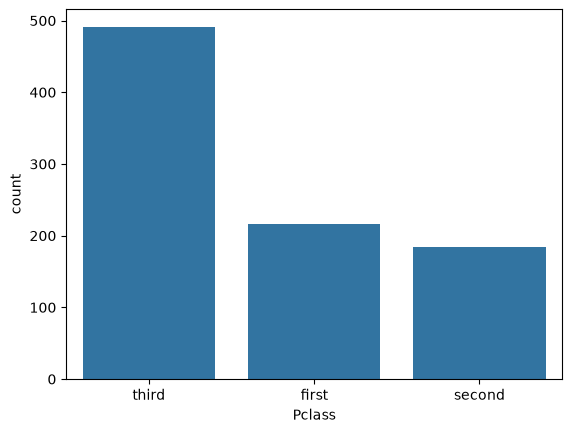

In [85]:
sns.countplot(data = df, x=df['Pclass'])

In [86]:
(df['Pclass'].value_counts()/len(df))* 100

Pclass
third     55.106622
first     24.242424
second    20.650954
Name: count, dtype: float64

In [87]:
Pclass_count = df['Pclass'].value_counts()
Pclass_label = df['Pclass'].unique()

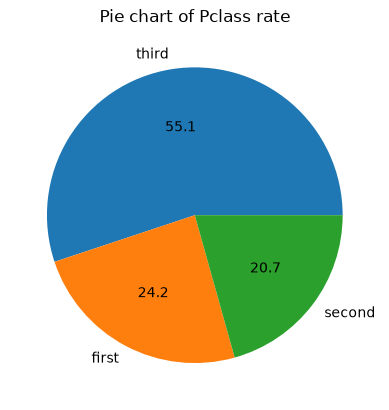

In [88]:
plt.pie(Pclass_count,labels =Pclass_label, autopct="%1.1f")
plt.title('Pie chart of Pclass rate')
plt.show()

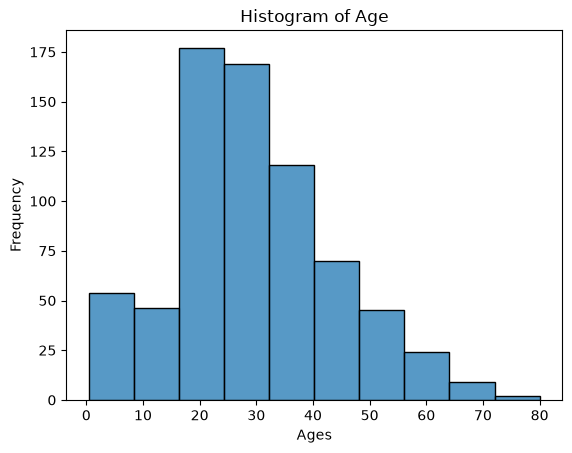

In [89]:
sns.histplot(df['Age'], bins = 10)
plt.title('Histogram of Age')
plt.xlabel('Ages')
plt.ylabel('Frequency')
plt.show()

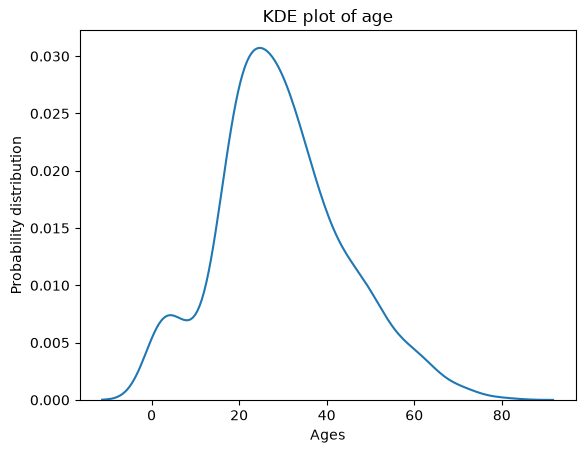

In [90]:
sns.kdeplot(df['Age'])
plt.title('KDE plot of age')
plt.xlabel('Ages')
plt.ylabel('Probability distribution')
plt.show()

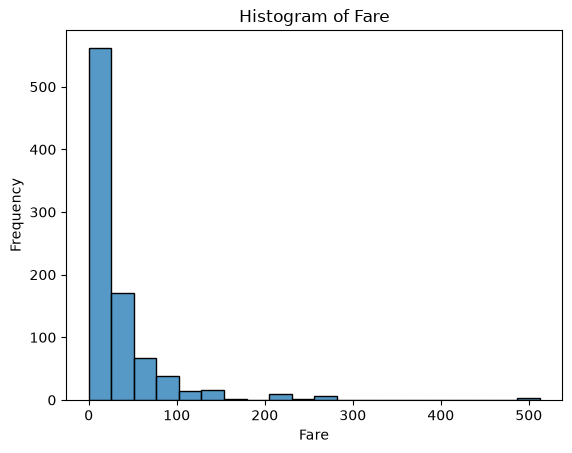

In [91]:
sns.histplot(df['Fare'], bins = 20)
plt.title('Histogram of Fare')
plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.show()

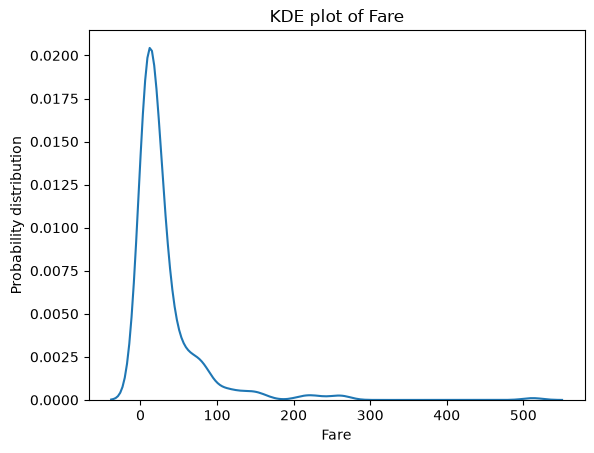

In [92]:
sns.kdeplot(df['Fare'])
plt.title('KDE plot of Fare')
plt.xlabel('Fare')
plt.ylabel('Probability distribution')
plt.show()

<Axes: ylabel='Fare'>

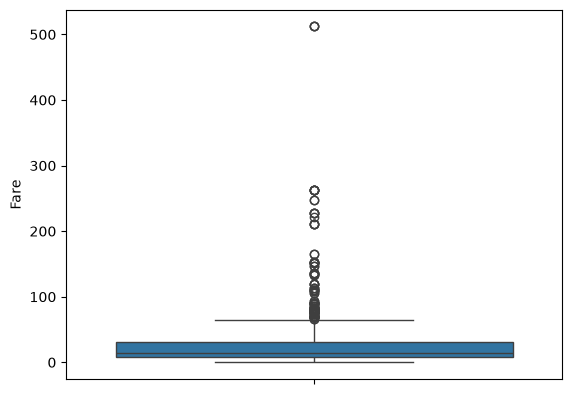

In [93]:
sns.boxplot(df['Fare'])

Multi variate Analysis

<Axes: xlabel='Sex', ylabel='count'>

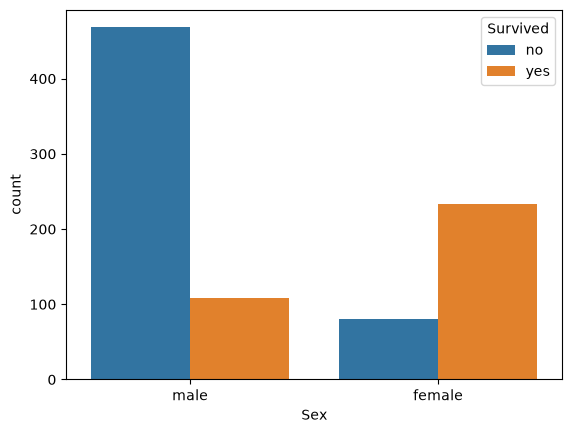

In [94]:
sns.countplot(data=df, x=df['Sex'],hue=df['Survived'])

In [95]:
gender_split = df.groupby('Sex')['Survived'].value_counts(normalize=True)

print(gender_split)

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64


<Axes: xlabel='Pclass', ylabel='count'>

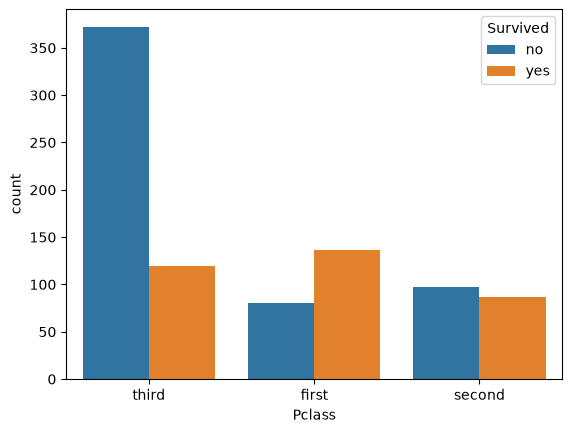

In [96]:
sns.countplot(data=df, x=df['Pclass'],hue=df['Survived'])

In [97]:
gender_split = df.groupby('Pclass')['Survived'].value_counts(normalize=True)

print(gender_split)

Pclass  Survived
first   yes         0.629630
        no          0.370370
second  no          0.527174
        yes         0.472826
third   no          0.757637
        yes         0.242363
Name: proportion, dtype: float64


<Axes: xlabel='Pclass', ylabel='Fare'>

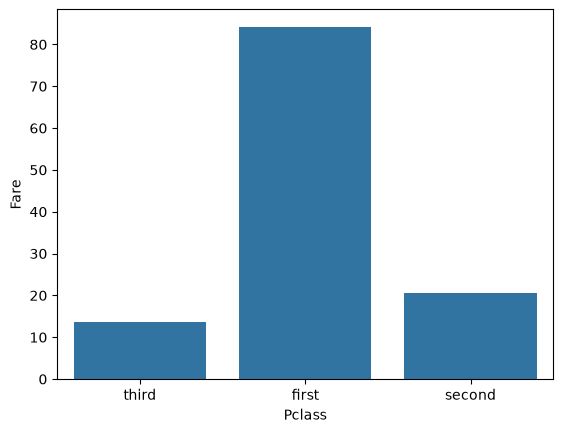

In [98]:
sns.barplot(x=df['Pclass'], y=df['Fare'],errorbar= None)

<Axes: xlabel='Survived', ylabel='Age'>

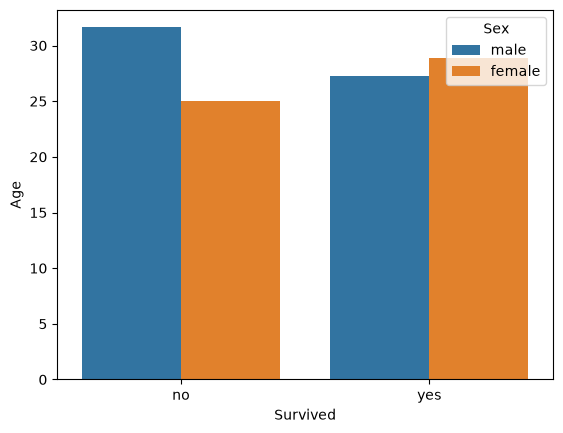

In [99]:
sns.barplot(x=df['Survived'], y=df['Age'],hue=df['Sex'],errorbar= None)

<Axes: xlabel='Age', ylabel='Density'>

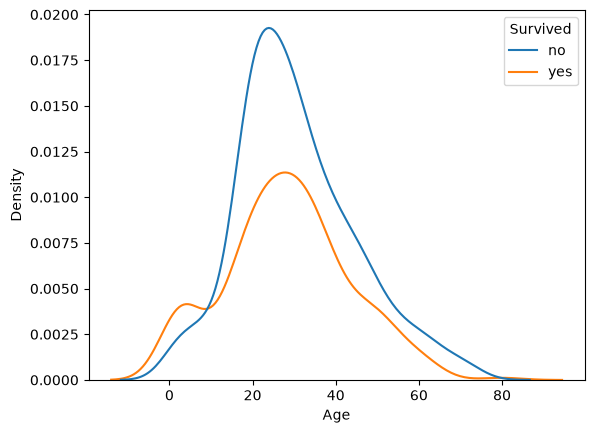

In [100]:
sns.kdeplot(data = df, x ='Age', hue = 'Survived')

In [101]:
# df = sns.load_dataset('tips')
# df

In [102]:
# sns.scatterplot(data = df,
#                 x = 'total_bill',
#                 y='tip',
#                 hue='sex',
#                 size='size')

In [103]:
# pip install ydata_profiling 


In [104]:
# from ydata_profiling import ProfileReport

# profile = ProfileReport(df,title='Titanic Profile Report')
# profile.to_file('my_report.html')

In [105]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


Module-3

In [106]:
df.drop(['PassengerId','Name','Ticket'],axis=1,inplace=True)

In [107]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


In [108]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

In [109]:
# df.drop(['Cabin'],axis=1,inplace=True)

In [110]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


In [111]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

In [112]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [113]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.5,0,0,28.5000,C124,S
733,second,male,23.0,0,0,13.0000,NaN,S
382,third,male,32.0,0,0,7.9250,NaN,S
704,third,male,26.0,1,0,7.8542,NaN,S
813,third,female,6.0,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S
270,first,male,NaN,0,0,31.0000,NaN,S
860,third,male,41.0,2,0,14.1083,NaN,S
435,first,female,14.0,1,2,120.0000,B96 B98,S


In [114]:
y_train


331     no
733     no
382     no
704     no
813     no
      ... 
106    yes
270     no
860     no
435    yes
102     no
Name: Survived, Length: 712, dtype: str

In [115]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
709,third,male,NaN,1,1,15.2458,NaN,C
439,second,male,31.0,0,0,10.5000,NaN,S
840,third,male,20.0,0,0,7.9250,NaN,S
720,second,female,6.0,0,1,33.0000,NaN,S
39,third,female,14.0,1,0,11.2417,NaN,C
...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,NaN,S
773,third,male,NaN,0,0,7.2250,NaN,C
25,third,female,38.0,1,5,31.3875,NaN,S
84,second,female,17.0,0,0,10.5000,NaN,S


In [116]:
y_test

709    yes
439     no
840     no
720    yes
39     yes
      ... 
433     no
773     no
25     yes
84     yes
10     yes
Name: Survived, Length: 179, dtype: str

Mean imput

In [117]:
X_train.isnull().sum()

Pclass        0
Sex           0
Age         140
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      2
dtype: int64

In [118]:
X_test.isnull().sum()

Pclass        0
Sex           0
Age          37
SibSp         0
Parch         0
Fare          0
Cabin       134
Embarked      0
dtype: int64

In [119]:
age_mean = X_train['Age'].mean()

X_train['age_mean_imputor'] = X_train['Age'].fillna(age_mean)
X_train


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor
331,first,male,45.5,0,0,28.5000,C124,S,45.500000
733,second,male,23.0,0,0,13.0000,NaN,S,23.000000
382,third,male,32.0,0,0,7.9250,NaN,S,32.000000
704,third,male,26.0,1,0,7.8542,NaN,S,26.000000
813,third,female,6.0,4,2,31.2750,NaN,S,6.000000
...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S,21.000000
270,first,male,NaN,0,0,31.0000,NaN,S,29.498846
860,third,male,41.0,2,0,14.1083,NaN,S,41.000000
435,first,female,14.0,1,2,120.0000,B96 B98,S,14.000000


In [120]:
X_train.isnull().sum()

Pclass                0
Sex                   0
Age                 140
SibSp                 0
Parch                 0
Fare                  0
Cabin               553
Embarked              2
age_mean_imputor      0
dtype: int64

In [121]:
age_mean = X_test['Age'].mean()

X_test['age_mean_imputer'] = X_test['Age'].fillna(age_mean)

In [122]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputer
709,third,male,NaN,1,1,15.2458,NaN,C,30.505845
439,second,male,31.0,0,0,10.5000,NaN,S,31.000000
840,third,male,20.0,0,0,7.9250,NaN,S,20.000000
720,second,female,6.0,0,1,33.0000,NaN,S,6.000000
39,third,female,14.0,1,0,11.2417,NaN,C,14.000000
...,...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,NaN,S,17.000000
773,third,male,NaN,0,0,7.2250,NaN,C,30.505845
25,third,female,38.0,1,5,31.3875,NaN,S,38.000000
84,second,female,17.0,0,0,10.5000,NaN,S,17.000000


Median imput

In [123]:
age_median = X_train['Age'].median()
X_train['age_median_imput'] = X_train['Age'].fillna(age_median)


In [124]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,age_median_imput
331,first,male,45.5,0,0,28.5000,C124,S,45.500000,45.5
733,second,male,23.0,0,0,13.0000,NaN,S,23.000000,23.0
382,third,male,32.0,0,0,7.9250,NaN,S,32.000000,32.0
704,third,male,26.0,1,0,7.8542,NaN,S,26.000000,26.0
813,third,female,6.0,4,2,31.2750,NaN,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S,21.000000,21.0
270,first,male,NaN,0,0,31.0000,NaN,S,29.498846,28.0
860,third,male,41.0,2,0,14.1083,NaN,S,41.000000,41.0
435,first,female,14.0,1,2,120.0000,B96 B98,S,14.000000,14.0


In [125]:
age_median = X_test['Age'].median()
X_test['age_median_imput'] = X_test['Age'].fillna(age_median)


In [126]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputer,age_median_imput
709,third,male,NaN,1,1,15.2458,NaN,C,30.505845,29.0
439,second,male,31.0,0,0,10.5000,NaN,S,31.000000,31.0
840,third,male,20.0,0,0,7.9250,NaN,S,20.000000,20.0
720,second,female,6.0,0,1,33.0000,NaN,S,6.000000,6.0
39,third,female,14.0,1,0,11.2417,NaN,C,14.000000,14.0
...,...,...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,NaN,S,17.000000,17.0
773,third,male,NaN,0,0,7.2250,NaN,C,30.505845,29.0
25,third,female,38.0,1,5,31.3875,NaN,S,38.000000,38.0
84,second,female,17.0,0,0,10.5000,NaN,S,17.000000,17.0


In [127]:
X_train


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,age_median_imput
331,first,male,45.5,0,0,28.5000,C124,S,45.500000,45.5
733,second,male,23.0,0,0,13.0000,NaN,S,23.000000,23.0
382,third,male,32.0,0,0,7.9250,NaN,S,32.000000,32.0
704,third,male,26.0,1,0,7.8542,NaN,S,26.000000,26.0
813,third,female,6.0,4,2,31.2750,NaN,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S,21.000000,21.0
270,first,male,NaN,0,0,31.0000,NaN,S,29.498846,28.0
860,third,male,41.0,2,0,14.1083,NaN,S,41.000000,41.0
435,first,female,14.0,1,2,120.0000,B96 B98,S,14.000000,14.0


<Axes: xlabel='age_mean_imputor', ylabel='Density'>

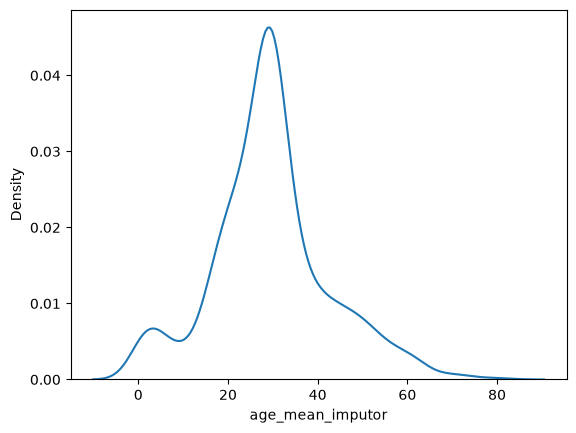

In [128]:
sns.kdeplot(data = X_train, x='age_mean_imputor')

<Axes: xlabel='age_median_imput', ylabel='Density'>

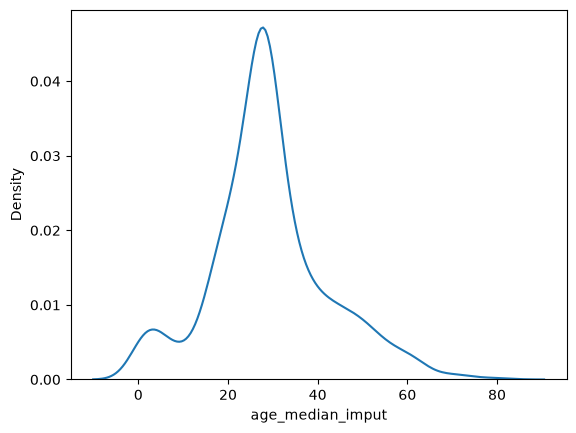

In [129]:
sns.kdeplot(data = X_train, x='age_median_imput')

In [130]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

age_imputer.fit(X_train[['Age']])

X_train['Age'] = age_imputer.transform(X_train[['Age']])

In [131]:
X_train.isnull().sum()

Pclass                0
Sex                   0
Age                   0
SibSp                 0
Parch                 0
Fare                  0
Cabin               553
Embarked              2
age_mean_imputor      0
age_median_imput      0
dtype: int64

In [132]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,age_median_imput
331,first,male,45.500000,0,0,28.5000,C124,S,45.500000,45.5
733,second,male,23.000000,0,0,13.0000,NaN,S,23.000000,23.0
382,third,male,32.000000,0,0,7.9250,NaN,S,32.000000,32.0
704,third,male,26.000000,1,0,7.8542,NaN,S,26.000000,26.0
813,third,female,6.000000,4,2,31.2750,NaN,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,NaN,S,21.000000,21.0
270,first,male,29.498846,0,0,31.0000,NaN,S,29.498846,28.0
860,third,male,41.000000,2,0,14.1083,NaN,S,41.000000,41.0
435,first,female,14.000000,1,2,120.0000,B96 B98,S,14.000000,14.0


In [133]:
X_train.drop(['age_mean_imputor','age_median_imput'],axis=1,inplace=True)
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.500000,0,0,28.5000,C124,S
733,second,male,23.000000,0,0,13.0000,NaN,S
382,third,male,32.000000,0,0,7.9250,NaN,S
704,third,male,26.000000,1,0,7.8542,NaN,S
813,third,female,6.000000,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,NaN,S
270,first,male,29.498846,0,0,31.0000,NaN,S
860,third,male,41.000000,2,0,14.1083,NaN,S
435,first,female,14.000000,1,2,120.0000,B96 B98,S


In [134]:
age_imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

age_imputer.fit(X_test[['Age']])

X_test['Age'] = age_imputer.transform(X_test[['Age']])

In [135]:
X_test.isnull().sum()

Pclass                0
Sex                   0
Age                   0
SibSp                 0
Parch                 0
Fare                  0
Cabin               134
Embarked              0
age_mean_imputer      0
age_median_imput      0
dtype: int64

In [136]:
X_test.drop(['age_mean_imputer','age_median_imput'],axis=1, inplace=True)
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
709,third,male,30.505845,1,1,15.2458,NaN,C
439,second,male,31.000000,0,0,10.5000,NaN,S
840,third,male,20.000000,0,0,7.9250,NaN,S
720,second,female,6.000000,0,1,33.0000,NaN,S
39,third,female,14.000000,1,0,11.2417,NaN,C
...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,NaN,S
773,third,male,30.505845,0,0,7.2250,NaN,C
25,third,female,38.000000,1,5,31.3875,NaN,S
84,second,female,17.000000,0,0,10.5000,NaN,S


<Axes: xlabel='Embarked', ylabel='count'>

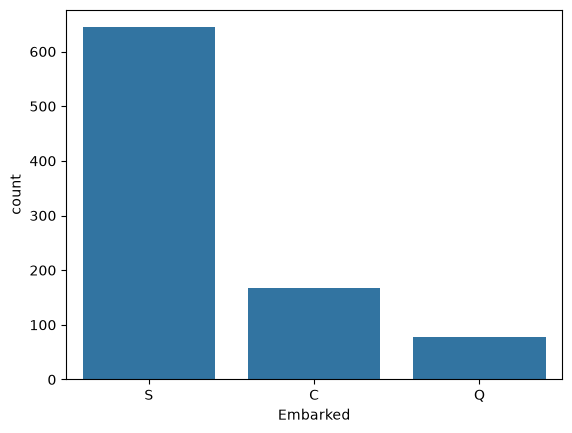

In [137]:
sns.countplot(data=df, x=df['Embarked'])

In [138]:
embarked_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

embarked_imputer.fit(X_train[['Embarked']])

#transform both train and test data

X_train['Embarked'] = embarked_imputer.transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_imputer.transform(X_test[['Embarked']]).ravel()

<Axes: xlabel='Cabin', ylabel='count'>

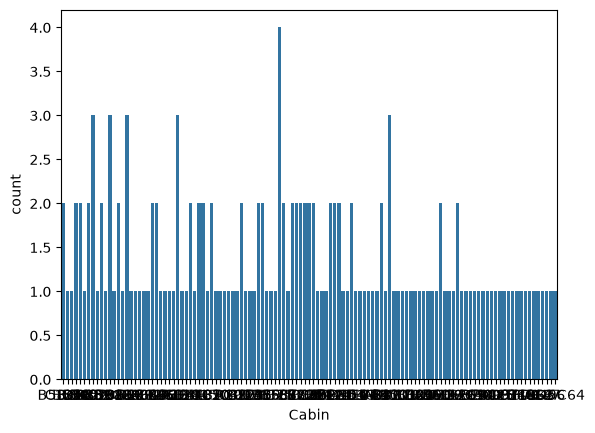

In [141]:
sns.countplot(data=df, x=X_train['Cabin'])

In [142]:
cabin_imputer = SimpleImputer(missing_values=np.nan, strategy='constant',fill_value ='Missing',add_indicator=True)

cabin_imputer.fit(X_train[['Cabin']])

#transform both train and test data

X_train[['Cabin','cabin_missing_indicator']] = cabin_imputer.transform(X_train[['Cabin']])
X_test[['Cabin','cabin_missing_indicator']] = cabin_imputer.transform(X_test[['Cabin']])

In [143]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
331,first,male,45.500000,0,0,28.5000,C124,S,False
733,second,male,23.000000,0,0,13.0000,Missing,S,True
382,third,male,32.000000,0,0,7.9250,Missing,S,True
704,third,male,26.000000,1,0,7.8542,Missing,S,True
813,third,female,6.000000,4,2,31.2750,Missing,S,True
...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,Missing,S,True
270,first,male,29.498846,0,0,31.0000,Missing,S,True
860,third,male,41.000000,2,0,14.1083,Missing,S,True
435,first,female,14.000000,1,2,120.0000,B96 B98,S,False


In [144]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
709,third,male,30.505845,1,1,15.2458,Missing,C,True
439,second,male,31.000000,0,0,10.5000,Missing,S,True
840,third,male,20.000000,0,0,7.9250,Missing,S,True
720,second,female,6.000000,0,1,33.0000,Missing,S,True
39,third,female,14.000000,1,0,11.2417,Missing,C,True
...,...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,Missing,S,True
773,third,male,30.505845,0,0,7.2250,Missing,C,True
25,third,female,38.000000,1,5,31.3875,Missing,S,True
84,second,female,17.000000,0,0,10.5000,Missing,S,True


In [145]:
X_train.isnull().sum()

Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Cabin                      0
Embarked                   0
cabin_missing_indicator    0
dtype: int64